# Tutorial: Picket-Fence Model Hamiltonian

## Introduction

The **Picket-Fence model** describes a one-dimensional chain of sites (the "bus" or "wire") where each bus site is coupled to its own isolated "picket" site. This creates a comb-like (or picket-fence) topology:

```
  P0    P1    P2    P3      (picket sites)
  |     |     |     |
  B0 -- B1 -- B2 -- B3      (bus sites)
```

Each picket site interacts *only* with its corresponding bus site. The bus sites form a linear chain with nearest-neighbor hopping.

**Why is this model interesting?**
This model introduces controlled localization via side-coupled states, making it ideal for studying the **transport vs. localization crossover**: as the bus–picket coupling $v$ increases, electrons transition from delocalized (metallic) states on the bus chain to localized (insulating) states on isolated dimers.

### Features demonstrated in this tutorial

- Defining a custom connectivity matrix for a picket-fence topology
- Mapping between spatial and spin-orbital bases
- Generating 0, 1, and 2-electron integrals in spatial and spin-orbital bases
- Solving for the ground state energy using PySCF FCI (`fci.direct_spin1`)
- Verifying HamHub integral structure against expected picket-fence topology
- **Reduced Hamiltonian verification using the geminal basis**
- Sanity checks at limiting cases ($v_{\rm ratio} = 0$ and $v_{\rm ratio} \to \infty$)
- **Eigenstate Localization Analysis via Inverse Participation Ratio (IPR)**
- Visualizing the localized ↔ delocalized transition
- Scaling behavior and extensibility of the model
- Saving integrals to `.npz` and `.fcidump` formats

## Mathematical Hamiltonian

We define the Picket-Fence Hamiltonian as:

\begin{equation}
\hat{H} =
\sum_{i \in \text{bus}, \sigma} t \, a_{i\sigma}^\dagger a_{i+1,\sigma}
+ \sum_{i \in \text{bus}, \sigma} v \, (a_{i\sigma}^\dagger a_{p_i\sigma} + a_{p_i\sigma}^\dagger a_{i\sigma})
+ \sum_{i,\sigma} \epsilon_i \, \hat{n}_{i\sigma}
+ \sum_i U_i \, \hat{n}_{i\uparrow} \hat{n}_{i\downarrow}
\end{equation}

where:

| Parameter | Description |
|---|---|
| $t$ | Bus–bus hopping integral (energy scale). |
| $v$ | Bus–picket coupling strength. |
| $v_{\text{ratio}} = v/|t|$ | Dimensionless coupling (used in plots). |
| $\epsilon_i$ | On-site energy of site $i$. |
| $U_i$ | On-site Coulomb repulsion. |
| $p_i$ | Picket site coupled to bus site $i$. |

This model can be interpreted as a **Hubbard Hamiltonian on a bipartite graph** with constrained connectivity (picket-fence topology).

For this tutorial, we set:
- Bus–bus hopping: $t = -1$ (sets the energy scale)
- Bus–picket coupling: $v = v_{\text{ratio}} \cdot |t|$ (variable)
- On-site energy: $\varepsilon = 0$ for all sites
- On-site repulsion: $U$ for all sites

## Basis Representation

The `ModelHamiltonian` package operates in two primary bases:

- **Spatial orbital basis**:
  - Indices: $p, q \in \{1, \ldots, N\}$
- **Spin-orbital basis**:
  - Indices: $p\sigma$, where $\sigma \in \{\alpha, \beta\}$

Mapping rules (see MolKit tutorial):

$$
h_{pq}^{\alpha\alpha} = h_{pq}^{\beta\beta} = h_{pq}
$$

$$
V_{pqrs}^{\alpha\alpha\alpha\alpha} = V_{pqrs}^{\text{spatial}}
$$

Mixed-spin terms vanish:
$$
V^{\alpha\beta} = 0
$$

## 1. Setup and Imports

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from pyscf import fci
from moha import HamHub
from moha.molkit.hamiltonians import MolHam
from moha.molkit.utils.tools import to_geminal
import warnings

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)

## 2. Defining the Picket-Fence Connectivity

We build a picket-fence system with `N_bus = 4` bus sites and 4 picket sites (total 8 sites).

The connectivity matrix is an $8 \times 8$ symmetric matrix constructed as follows:

- **Bus chain:** Sites $0, 1, 2, 3$ are connected with nearest-neighbor hopping amplitude 1.
- **Bus–picket coupling:** Each bus site $i$ is coupled to picket site $i + N_{\text{bus}}$ with amplitude $v_{\text{ratio}}$.
- **Picket sites** (4, 5, 6, 7) have **no** connections to each other.

The connectivity matrix fully defines the graph structure of the Hamiltonian — `HamHub` reads this matrix and automatically constructs the hopping terms $h_{pq} = \beta \cdot c_{pq}$ (where $c_{pq}$ is the matrix entry), so no manual term construction is needed.

In [15]:
def build_picket_fence_connectivity(N_bus, v_ratio=1.0):
    """Build the connectivity matrix for a picket-fence system.

    Parameters
    ----------
    N_bus : int
        Number of bus sites.
    v_ratio : float
        Dimensionless bus-picket coupling v / |t|.

    Returns
    -------
    np.ndarray
        Connectivity matrix of shape (2*N_bus, 2*N_bus).
    """
    N_total = 2 * N_bus
    conn = np.zeros((N_total, N_total))
    # Bus chain: nearest-neighbor connections (amplitude = 1)
    for i in range(N_bus - 1):
        conn[i, i + 1] = conn[i + 1, i] = 1.0
    # Bus-picket coupling (amplitude = v_ratio)
    for i in range(N_bus):
        conn[i, i + N_bus] = conn[i + N_bus, i] = v_ratio
    return conn

N_bus = 4
v_ratio = 0.5  # dimensionless: v / |t|

conn = build_picket_fence_connectivity(N_bus, v_ratio=v_ratio)
print("Connectivity matrix (v_ratio = 0.5):")
print(conn)

Connectivity matrix (v_ratio = 0.5):
[[0.  1.  0.  0.  0.5 0.  0.  0. ]
 [1.  0.  1.  0.  0.  0.5 0.  0. ]
 [0.  1.  0.  1.  0.  0.  0.5 0. ]
 [0.  0.  1.  0.  0.  0.  0.  0.5]
 [0.5 0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.5 0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.5 0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.5 0.  0.  0.  0. ]]


## 3. Instantiating the Hamiltonian

We use the `HamHub` (Hubbard) class from the Model Hamiltonian package. The connectivity matrix fully encodes the picket-fence topology.

**Parameters:**
- `alpha = 0`: on-site energy $\varepsilon_i = 0$ for all sites
- `beta = -1`: sets the energy scale for the hopping (the connectivity matrix entries scale $\beta$)
- `u_onsite`: on-site Coulomb repulsion $U$ for each site

The resulting one-body matrix entries are:

$$h_{pq} = \alpha \, \delta_{pq} + \beta \cdot c_{pq}$$

where $c_{pq}$ is the connectivity matrix value.

In [16]:
N_total = 2 * N_bus
U_val = 2.0  # on-site Coulomb repulsion

ham_hub = HamHub(
    connectivity=conn,
    alpha=0,
    beta=-1,
    u_onsite=np.full(N_total, U_val),
)

print(f"Number of sites: {ham_hub.n_sites}")
print(f"System: {N_bus} bus sites + {N_bus} picket sites = {N_total} total sites")

Number of sites: 8
System: 4 bus sites + 4 picket sites = 8 total sites


## 4. Generating Integrals

The Model Hamiltonian package generates 0-, 1-, and 2-electron integrals. These can be obtained in either the **spatial** or **spin-orbital** basis.

### 4.1 Zero-body integral (energy shift)

In [17]:
e0 = ham_hub.generate_zero_body_integral()
print(f"Zero-body integral (energy shift): {e0}")

Zero-body integral (energy shift): 0


### 4.2 One-body integrals

The one-body integral matrix $h_{pq}$ encodes the hopping terms and on-site energies.

In [18]:
# Spatial basis
h1_spatial = ham_hub.generate_one_body_integral(dense=True, basis='spatial basis')
print("One-body integrals (spatial basis):")
print(f"  Shape: {h1_spatial.shape}")
print(h1_spatial)

print("\n" + "-" * 60 + "\n")

# Spin-orbital basis
h1_spin = ham_hub.generate_one_body_integral(dense=True, basis='spinorbital basis')
print("One-body integrals (spin-orbital basis):")
print(f"  Shape: {h1_spin.shape}")

One-body integrals (spatial basis):
  Shape: (8, 8)
[[ 0.  -1.   0.   0.  -0.5  0.   0.   0. ]
 [-1.   0.  -1.   0.   0.  -0.5  0.   0. ]
 [ 0.  -1.   0.  -1.   0.   0.  -0.5  0. ]
 [ 0.   0.  -1.   0.   0.   0.   0.  -0.5]
 [-0.5  0.   0.   0.   0.   0.   0.   0. ]
 [ 0.  -0.5  0.   0.   0.   0.   0.   0. ]
 [ 0.   0.  -0.5  0.   0.   0.   0.   0. ]
 [ 0.   0.   0.  -0.5  0.   0.   0.   0. ]]

------------------------------------------------------------

One-body integrals (spin-orbital basis):
  Shape: (16, 16)


### 4.3 Two-body integrals

The two-body integral tensor $V_{pqrs}$ encodes the electron–electron repulsion.

In [19]:
# Spatial basis with 4-fold symmetry
h2_spatial = ham_hub.generate_two_body_integral(dense=True, basis='spatial basis', sym=4)
print("Two-body integrals (spatial basis):")
print(f"  Shape: {h2_spatial.shape}")

print("\n" + "-" * 60 + "\n")

# Spin-orbital basis with 4-fold symmetry
h2_spin = ham_hub.generate_two_body_integral(dense=True, basis='spinorbital basis', sym=4)
print("Two-body integrals (spin-orbital basis):")
print(f"  Shape: {h2_spin.shape}")

Two-body integrals (spatial basis):
  Shape: (8, 8, 8, 8)

------------------------------------------------------------

Two-body integrals (spin-orbital basis):
  Shape: (16, 16, 16, 16)


## 5. FCI Ground State Solver

### Integral Convention

- `ModelHamiltonian` outputs **physicists' notation** $\langle p q | r s\rangle$
- `PySCF` expects **chemists' notation** $(p r | q s)$

Transformation:
$$
V_{\text{phys}}(p,q,r,s) \rightarrow V_{\text{chem}}(p,r,q,s)
$$

In [20]:
def solve_fci(h1, h2, norb, nelec, ecore=0.0):
    """Solve the FCI problem using PySCF's fci.direct_spin1.

    Converts integrals from physicists' to chemists' notation before calling
    the solver: V_chem(p, r, q, s) = V_phys(p, q, r, s).
    """
    h2_chem = np.einsum('pqrs -> prqs', h2)
    e, ci_vec = fci.direct_spin1.kernel(h1, h2_chem, norb, nelec, ecore=ecore, tol=1e-12)
    return e, ci_vec

N_elec = N_total  # half-filling: one electron per site
nelec = (N_elec // 2, N_elec // 2)  # (n_alpha, n_beta)

# Use the spatial-basis integrals
h1 = h1_spatial
h2 = h2_spatial

e_fci_moha, ci_vec = solve_fci(h1, h2, N_total, nelec, ecore=e0)
print(f"FCI ground state energy (v_ratio={v_ratio}): {e_fci_moha:.10f}")

FCI ground state energy (v_ratio=0.5): -4.5579753175


## 6. Verifying the Integral Structure

We verify that `HamHub` produced the correct one-body matrix by checking its matrix elements against the expected picket-fence topology.

For a system with `beta=-1` and `alpha=0`, the formula $h_{pq} = \alpha\,\delta_{pq} + \beta \cdot c_{pq}$ gives:

| Bond type | Connectivity value | Expected $h_{pq}$ |
|---|---|---|
| Bus–bus | $c_{i,i+1} = 1$ | $\beta \cdot 1 = -1$ |
| Bus–picket | $c_{i,i+N_{\text{bus}}} = v_{\text{ratio}}$ | $\beta \cdot v_{\text{ratio}} = -0.5$ |
| On-site | $\alpha = 0$ | $0$ |

In [21]:
beta = -1.0

# Verify bus chain hoppings
bus_hoppings = [h1[i, i+1] for i in range(N_bus - 1)]
expected_bus = beta * 1.0
print(f"Bus-chain hopping values:   {bus_hoppings}")
assert all(np.isclose(v, expected_bus) for v in bus_hoppings)
print(f"  Expected: {expected_bus}  ✔")

# Verify bus-picket couplings
pic_hoppings = [h1[i, i + N_bus] for i in range(N_bus)]
expected_pic = beta * v_ratio
print(f"Bus-picket coupling values: {pic_hoppings}")
assert all(np.isclose(v, expected_pic) for v in pic_hoppings)
print(f"  Expected: {expected_pic}  ✔")

# Verify diagonal (on-site energies)
diag_vals = np.diag(h1)
print(f"Diagonal (on-site) values:  {diag_vals}")
assert np.allclose(diag_vals, 0.0)
print(f"  Expected: 0.0  ✔")

print("\nAll structural checks PASSED.")

Bus-chain hopping values:   [np.float64(-1.0), np.float64(-1.0), np.float64(-1.0)]
  Expected: -1.0  ✔
Bus-picket coupling values: [np.float64(-0.5), np.float64(-0.5), np.float64(-0.5), np.float64(-0.5)]
  Expected: -0.5  ✔
Diagonal (on-site) values:  [0. 0. 0. 0. 0. 0. 0. 0.]
  Expected: 0.0  ✔

All structural checks PASSED.


## 7. Reduced Hamiltonian & Geminal Verification

We use the `MolHam` class to verify the consistency between spin-orbital and geminal representations. The reduced Hamiltonian $k_{pqrs}$ encapsulates both one- and two-body terms into a single 4-index tensor.

### Formula
$$
k_{pqrs} = \frac{1}{2(N-1)} \left( h_{pq} \delta_{rs} + h_{rs} \delta_{pq} \right) + \frac{1}{2} V_{pqrs}
$$

In [22]:
# Wrap integrals in MolHam object
hami = MolHam(one_body=h1, two_body=h2, zero_body=e0)

# Obtain RDMs from FCI wavefunction
rdm1s, rdm2s = fci.direct_spin1.make_rdm12s(ci_vec, N_total, nelec)

# Construct spin-orbital RDM2 in physicists' notation
rdm2_spin = np.zeros((2 * N_total, 2 * N_total, 2 * N_total, 2 * N_total))
for i in range(N_total):
    for j in range(N_total):
        for k in range(N_total):
            for l in range(N_total):
                rdm2_spin[i, j, k, l] = rdm2s[0][i, k, j, l]  # aaaa
                rdm2_spin[i+N_total, j+N_total, k+N_total, l+N_total] = rdm2s[2][i, k, j, l]  # bbbb
                rdm2_spin[i, j+N_total, k, l+N_total] = rdm2s[1][i, k, j, l]  # abab
                rdm2_spin[i+N_total, j, k+N_total, l] = rdm2s[1][i, k, j, l]  # baba

# 1. Compute energy using spin-orbital basis
H_reduced = hami.to_reduced(n_elec=sum(nelec))
E_spin = np.sum(H_reduced * rdm2_spin)

# 2. Compute energy using geminal basis
H_gem = to_geminal(H_reduced, type='h2')
rdm_gem = to_geminal(rdm2_spin, type='rdm2')
E_gem = np.einsum('pq,pq', H_gem, rdm_gem)

print(f"E_spin-orbital: {E_spin:.10f}")
print(f"E_geminal:      {E_gem:.10f}")
print(f"FCI electronic energy: {e_fci_moha - e0:.10f}")
assert np.allclose(E_spin, E_gem)
assert np.allclose(E_spin, e_fci_moha - e0)
print("Consistency check PASSED: E_spin == E_gem == E_electronic")

E_spin-orbital: -4.5579753175
E_geminal:      -4.5579753175
FCI electronic energy: -4.5579753175
Consistency check PASSED: E_spin == E_gem == E_electronic


## 8. Sanity Check: Limiting Cases

Before running the full sweep, we verify the two limiting behaviors of the model at half-filling:

| Limit | Physical picture | Expected behavior |
|---|---|---|
| $v_{\text{ratio}} \to 0$ | Pickets decouple; system → pure $N_{\text{bus}}$-site chain | Energy dominated by bus chain; pickets carry zero hopping |
| $v_{\text{ratio}} \to \infty$ | Bus–bus hopping negligible; system → $N_{\text{bus}}$ independent dimers | $E \to N_{\text{bus}} \times E_{\text{dimer}}(v_{\text{ratio}})$ |

Both checks use the **full 8-site system** with 8 electrons (half-filling), ensuring consistent comparison.

In [23]:
# ---------------------------------------------------------------
# Limit 1: v_ratio → 0 (pickets decouple from bus)
# ---------------------------------------------------------------
# At v_ratio=0, the 8-site system splits into:
#   - A 4-site bus chain with 4 electrons
#   - 4 isolated picket sites with 4 electrons (1 per site → 0 kinetic energy)
# Full energy = E_bus + E_pickets = E_bus + 0 (no hopping on isolated sites)
# We verify by checking energy at a very small v_ratio.

eps = 1e-6  # effectively zero coupling
conn_eps = build_picket_fence_connectivity(N_bus, v_ratio=eps)
hub_eps = HamHub(connectivity=conn_eps, alpha=0, beta=-1, u_onsite=np.full(N_total, U_val))
e_eps, _ = solve_fci(
    hub_eps.generate_one_body_integral(dense=True, basis='spatial basis'),
    hub_eps.generate_two_body_integral(dense=True, basis='spatial basis', sym=4),
    N_total, nelec, ecore=hub_eps.generate_zero_body_integral()
)

# ---------------------------------------------------------------
# Limit 2: v_ratio → ∞ (strong dimer formation)
# ---------------------------------------------------------------
# At large v_ratio, the system → N_bus independent 2-site dimers.
# Each dimer: 1 bus site + 1 picket, with coupling v = beta * v_ratio.
# We compute the energy of ONE such dimer (2 sites, 2 electrons, 1↑+1↓)
# using the SAME v_ratio and compare N_bus × E_dimer to the full system.

v_large = 8.0

# Full 8-site system at v_large
conn_large = build_picket_fence_connectivity(N_bus, v_ratio=v_large)
hub_large = HamHub(connectivity=conn_large, alpha=0, beta=-1, u_onsite=np.full(N_total, U_val))
e_large, _ = solve_fci(
    hub_large.generate_one_body_integral(dense=True, basis='spatial basis'),
    hub_large.generate_two_body_integral(dense=True, basis='spatial basis', sym=4),
    N_total, nelec, ecore=hub_large.generate_zero_body_integral()
)

# Single dimer: 2-site system with coupling v_large (bus-picket bond only)
conn_dimer = np.array([[0, v_large], [v_large, 0]], dtype=float)
hub_dimer = HamHub(connectivity=conn_dimer, alpha=0, beta=-1, u_onsite=np.full(2, U_val))
e_dimer, _ = solve_fci(
    hub_dimer.generate_one_body_integral(dense=True, basis='spatial basis'),
    hub_dimer.generate_two_body_integral(dense=True, basis='spatial basis', sym=4),
    2, (1, 1), ecore=hub_dimer.generate_zero_body_integral()
)

print(f"Limit v_ratio → 0 (v_ratio = {eps}):")
print(f"  Full system energy:   {e_eps:.6f}")
print()
print(f"Limit v_ratio → ∞ (v_ratio = {v_large}):")
print(f"  Full system energy:        {e_large:.6f}")
print(f"  N_bus × single dimer:      {N_bus * e_dimer:.6f}")
print(f"  Relative difference:       {abs(e_large - N_bus * e_dimer) / abs(e_large):.4%}")
print()
print(f"Interpretation:")
print(f"  At v_ratio={eps}: purely bus-dominated; pickets are inert.")
print(f"  At v_ratio={v_large}: system ≈ {N_bus} independent dimers "
      f"(relative error = {abs(e_large - N_bus * e_dimer) / abs(e_large):.2%}).")

Limit v_ratio → 0 (v_ratio = 1e-06):
  Full system energy:   -2.596722

Limit v_ratio → ∞ (v_ratio = 8.0):
  Full system energy:        -62.218092
  N_bus × single dimer:      -62.031242
  Relative difference:       0.3003%

Interpretation:
  At v_ratio=1e-06: purely bus-dominated; pickets are inert.
  At v_ratio=8.0: system ≈ 4 independent dimers (relative error = 0.30%).


## 9. Eigenstate Localization Analysis via IPR

### Objective

We quantify the localization–delocalization transition by analyzing the single-particle density matrix and computing the **Inverse Participation Ratio (IPR)**.

### Key Idea

For a set of normalized site occupations $\{n_i\}$ (diagonal of the 1-RDM), define:

$$
\text{IPR} = \sum_i n_i^2 \qquad \text{where } \sum_i n_i = 1
$$

| IPR value | Physical meaning |
|---|---|
| $\text{IPR} \approx 1/N$ | Fully delocalized: electrons spread uniformly across all $N$ sites |
| $\text{IPR} \to 1$ | Strongly localized: one site dominates the occupation |

In the picket-fence model:
- Small $v_{\text{ratio}}$: electrons are delocalized across the bus chain → low IPR
- Large $v_{\text{ratio}}$: electrons localize onto bus–picket dimers → IPR rises

In [24]:
def compute_ipr(rdm1):
    """Compute IPR from the 1-body density matrix (alpha block).

    Uses diagonal site occupations as proxy for localization.

    Parameters
    ----------
    rdm1 : np.ndarray
        1-body density matrix (N x N).

    Returns
    -------
    float
        Inverse Participation Ratio.
    """
    occ = np.diag(rdm1)
    occ = occ / np.sum(occ)  # normalize to sum = 1
    return np.sum(occ ** 2)


v_values = np.linspace(0.1, 3.0, 30)
ipr_values = []

for v in v_values:
    c = build_picket_fence_connectivity(N_bus, v_ratio=v)
    h_ipr = HamHub(connectivity=c, alpha=0, beta=-1, u_onsite=np.full(N_total, U_val))
    h1_ipr = h_ipr.generate_one_body_integral(dense=True, basis='spatial basis')
    h2_ipr = h_ipr.generate_two_body_integral(dense=True, basis='spatial basis', sym=4)
    _, ci_v = solve_fci(h1_ipr, h2_ipr, N_total, nelec,
                        ecore=h_ipr.generate_zero_body_integral())
    rdm1_v, _ = fci.direct_spin1.make_rdm12s(ci_v, N_total, nelec)
    ipr_values.append(compute_ipr(rdm1_v[0]))  # alpha block

ipr_values = np.array(ipr_values)

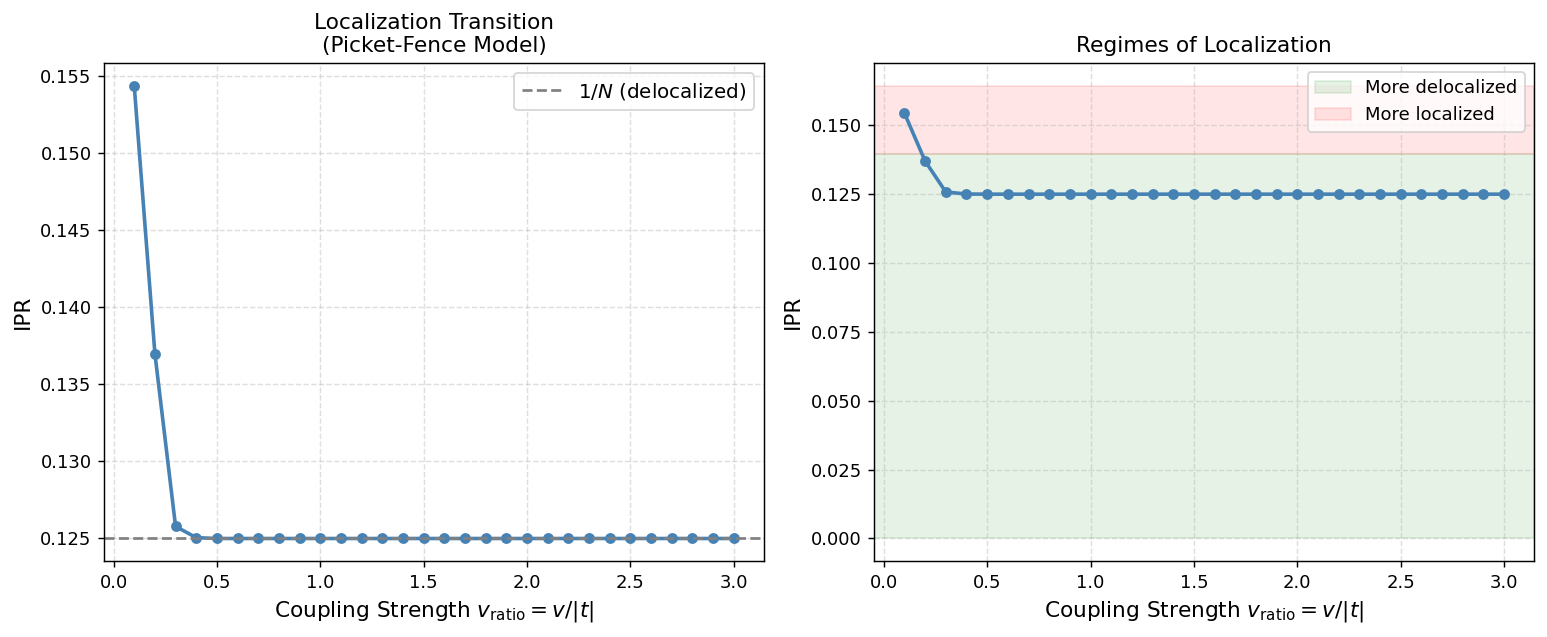

IPR bounds:
  Uniform delocalization reference (1/N): 0.1250
  IPR at v_ratio=0.1:                     0.1544
  IPR at v_ratio=3.0:                     0.1250


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=130)

# Panel 1: IPR vs coupling
axes[0].plot(v_values, ipr_values, 'o-', linewidth=2, markersize=5, color='steelblue')
axes[0].axhline(1 / N_total, linestyle='--', color='gray', label=r'$1/N$ (delocalized)')
axes[0].set_xlabel(r'Coupling Strength $v_{\rm ratio} = v/|t|$', fontsize=12)
axes[0].set_ylabel('IPR', fontsize=12)
axes[0].set_title('Localization Transition\n(Picket-Fence Model)', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.4)

# Panel 2: IPR interpretation zones
delocalized_ref = 1 / N_total
threshold = (delocalized_ref + ipr_values.max()) / 2
axes[1].plot(v_values, ipr_values, 'o-', linewidth=2, markersize=5, color='steelblue')
axes[1].axhspan(0, threshold, alpha=0.1, color='green', label='More delocalized')
axes[1].axhspan(threshold, ipr_values.max() + 0.01, alpha=0.1, color='red', label='More localized')
axes[1].set_xlabel(r'Coupling Strength $v_{\rm ratio} = v/|t|$', fontsize=12)
axes[1].set_ylabel('IPR', fontsize=12)
axes[1].set_title('Regimes of Localization', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print(f"IPR bounds:")
print(f"  Uniform delocalization reference (1/N): {1/N_total:.4f}")
print(f"  IPR at v_ratio=0.1:                     {ipr_values[0]:.4f}")
print(f"  IPR at v_ratio=3.0:                     {ipr_values[-1]:.4f}")

### Physical Insight

- **Small $v_{\text{ratio}}$:** IPR is small → electrons are spread across the bus → **delocalized / metallic regime**.
- **Large $v_{\text{ratio}}$:** IPR increases → electrons localize on bus–picket dimers → **insulating / localized regime**.

**Key result:** The picket-fence model exhibits a **continuous localization crossover** controlled by the dimensionless side-coupling strength $v_{\text{ratio}} = v/|t|$. This makes it a tractable model for studying transport vs. localization physics in quasi-1D systems.

## 10. Visualization: Ground State Energy vs. Coupling Strength

We sweep $v_{\text{ratio}}$ and compute the FCI ground state energy at each value.

In [26]:
energies = []

for v in v_values:
    c = build_picket_fence_connectivity(N_bus, v_ratio=v)
    h = HamHub(connectivity=c, alpha=0, beta=-1, u_onsite=np.full(N_total, U_val))
    e, _ = solve_fci(
        h.generate_one_body_integral(dense=True, basis='spatial basis'),
        h.generate_two_body_integral(dense=True, basis='spatial basis', sym=4),
        N_total, nelec, ecore=h.generate_zero_body_integral()
    )
    energies.append(e)

energies = np.array(energies)

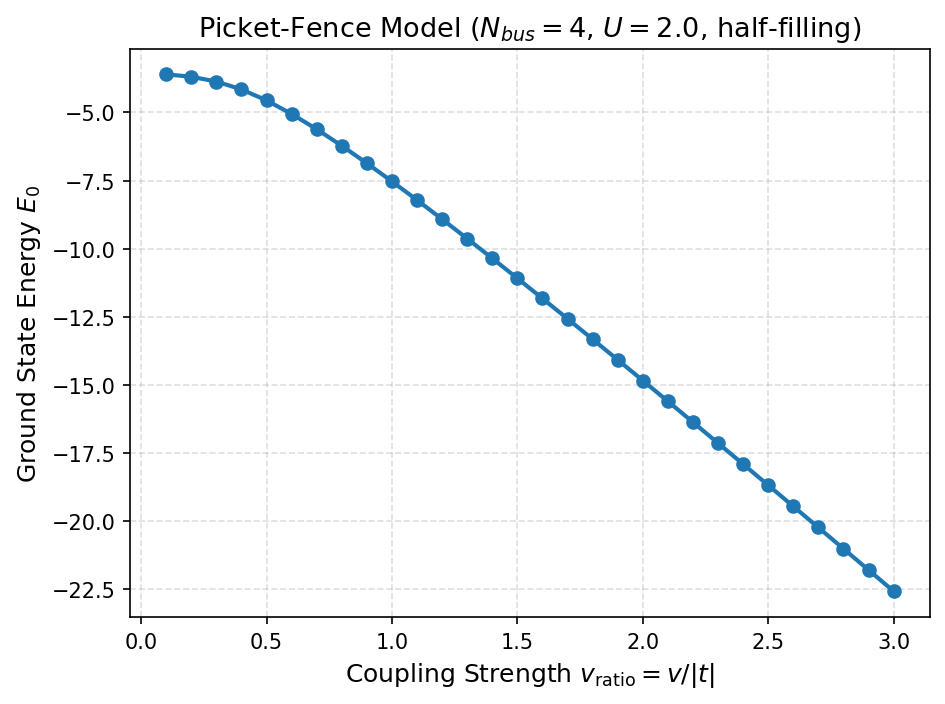

In [27]:
plt.figure(dpi=150)
plt.plot(v_values, energies, 'o-', linewidth=2, markersize=6)
plt.xlabel(r'Coupling Strength $v_{\rm ratio} = v/|t|$', fontsize=12)
plt.ylabel(r'Ground State Energy $E_0$', fontsize=12)
plt.title(rf'Picket-Fence Model ($N_{{bus}}={N_bus}$, $U={U_val}$, half-filling)', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## Physical Interpretation

- **For small coupling ($v_{\text{ratio}} \ll 1$):** Pickets behave as weak perturbations. The energy is dominated by the delocalized bus chain.
- **For large coupling ($v_{\text{ratio}} \gg 1$):** The system forms strongly hybridized dimers between each bus site and its picket. The energy decreases significantly as electrons localize on these strong bonds.

This crossover reflects a transition from a **delocalized 1D metallic-like chain** to a **localized collection of dimers**.

## Scaling Considerations

### Hilbert Space Growth

At half-filling ($N$ electrons on $2N$ spin-orbitals), the FCI Hilbert space dimension is:

$$
\dim(\mathcal{H}) = \binom{2N}{N}
$$

| Sites $N$ | Hilbert space dim | Memory (float64) |
|---|---|---|
| 4 | 70 | ~40 KB |
| 6 | 924 | ~7 MB |
| 8 | 12870 | ~1.3 GB |
| 10 | 184756 | ~270 GB |

### The Exponential Wall

FCI scales **exponentially** with system size — both in memory ($O(\dim^2)$ for the Hamiltonian matrix) and runtime ($O(\dim^3)$ for diagonalization). Beyond $N \approx 6$–7 sites per spin, FCI is computationally intractable.

For larger picket-fence systems, alternative methods include:
- **DMRG** (Density Matrix Renormalization Group) — exploits 1D entanglement structure
- **Tensor Networks** — generalizes to 2D geometries
- **Mean-Field / Hartree-Fock** — upper bound, fast but misses correlations

## Extensions

This framework can be extended to:
- **Disordered picket-fence:** Random on-site energies $\epsilon_i$ to study Anderson localization.
- **Multi-picket systems:** More than one side-group per bus site.
- **Long-range coupling:** Interactions beyond bus-bus and bus-picket pairs.
- **Time-dependent Hamiltonians:** External fields driving transport through the bus.

## 11. Data Persistence

The Model Hamiltonian package supports saving integrals in two formats:

1. **`.npz`** — NumPy compressed archive (keys: `e0`, `h1`, `h2`)
2. **`.fcidump`** — Standard quantum chemistry FCIDUMP format

### 11.1 Saving to `.npz`

In [28]:
# Save to npz
ham_hub.savez('picket_fence_integrals.npz')
print("Saved to picket_fence_integrals.npz")

# Verify the saved data
data = np.load('picket_fence_integrals.npz')
print(f"\nKeys in .npz file: {list(data.keys())}")
print(f"  e0 shape: scalar = {data['e0']}")
print(f"  h1 shape: {data['h1'].shape}")
print(f"  h2 shape: {data['h2'].shape}")

Saved to picket_fence_integrals.npz

Keys in .npz file: ['e0', 'h1', 'h2']
  e0 shape: scalar = 0
  h1 shape: (16, 16)
  h2 shape: (16, 16, 16, 16)


### 11.2 Saving to FCIDUMP format

In [29]:
# Save to FCIDUMP
ham_hub.save_fcidump('picket_fence.fcidump', nelec=N_elec)
print("Saved to picket_fence.fcidump")

# Show the first few lines of the FCIDUMP file
print("\nFirst 15 lines of picket_fence.fcidump:")
with open('picket_fence.fcidump', 'r') as f:
    for i, line in enumerate(f):
        if i < 15:
            print(f"  {line.rstrip()}")
        else:
            print("  ...")
            break

Saved to picket_fence.fcidump

First 15 lines of picket_fence.fcidump:
   &FCI NORB=16,NELEC=8,MS2=0,
    ORBSYM= 1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,
    ISYM=1
   &END
   2.0000000000000000e+00    9    9    1    1
   2.0000000000000000e+00   10   10    2    2
   2.0000000000000000e+00   11   11    3    3
   2.0000000000000000e+00   12   12    4    4
   2.0000000000000000e+00   13   13    5    5
   2.0000000000000000e+00   14   14    6    6
   2.0000000000000000e+00   15   15    7    7
   2.0000000000000000e+00   16   16    8    8
  -1.0000000000000000e+00    2    1    0    0
  -1.0000000000000000e+00    3    2    0    0
  -1.0000000000000000e+00    4    3    0    0
  ...


## Summary & Conclusion

In this tutorial, we demonstrated the full workflow for modeling a structured system:

1. **Graph-Based Definition**: Encoding the picket-fence topology via a connectivity matrix in `HamHub`.
2. **Integral Generation**: Extracting 0, 1, and 2-electron integrals in spatial and spin-orbital bases.
3. **Exact Solver**: Computing the ground state using PySCF's FCI (`fci.direct_spin1`).
4. **Pedagogical Verification**: 
   - Structural checks of the $h_{pq}$ matrix.
   - Consistency between spin-orbital and geminal energy representations.
   - Validation of limiting cases (isolated bus chain vs. isolated dimers).
5. **Physical Physics Insight**: 
   - Quantifying the **localization crossover** using the Inverse Participation Ratio (IPR).
   - Visualizing the transition from a delocalized energy regime to a localized dimer regime.

### Research Significance
The Picket-Fence model serves as a minimalist archetype for **quasi-1D systems with pendant groups**. By varying the coupling $v_{\rm ratio}$, one can simulate the transition between a conducting state (high delocalization) and an insulating state (strong localization). This tutorial provides the computational foundation for exploring such transitions in more complex model Hamiltonians.